# Gridworld: sampled episodes, exact values, and policy gradients

A fixed policy turns the finite-horizon MDP in `gridworld/model.py` into trajectories.
We will inspect action probabilities, draw one complete episode, and separate
policy sampling, environmental slip, and reward noise. Then we will compute
exact values by averaging over every possible outcome under the same fixed
policy, read spatial value/probability/advantage maps, and differentiate its
expected return with respect to the logits. Finally,
we will estimate that gradient from complete episodes with full-return REINFORCE
and reward-to-go, then subtract a fixed state baseline.
There is no training here.

From `rl_math`, run `uv sync --locked` and then
`uv run --locked jupyter lab notebooks/01_gridworld.ipynb`. The project
environment includes NumPy, Matplotlib, JupyterLab, and its Python kernel.
PyTorch handles differentiable probability/value calculations; NumPy owns the seeded random draws. Run
the cells in order from the repository root, `rl_math`, or this notebook's directory.

This notebook explicitly uses CUDA. The setup cell prints the GPU name;
logits, probabilities, exact values, and autograd derivatives stay on that device.
The library also supports `device="cpu"` for reference checks.


In [1]:
from pathlib import Path
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
import numpy as np
import torch
import platform
import sys

project = next(p for p in (Path.cwd(), Path.cwd().parent, Path.cwd() / "rl_math")
               if (p / "gridworld" / "model.py").is_file())
sys.path.insert(0, str(project))
from gridworld.model import Action, Gridworld, State
from common.returns import discounted_returns
from common.policy import Policy
from gridworld.policy import TabularSoftmaxPolicy
from gridworld.sampling import sample_episode
from gridworld.values import evaluate_policy
from gridworld.gradients import differentiate_policy
from gridworld.figures import FIGURE_SEEDS, POLICY_NAME, safe_route_policy
from gridworld.plotting import plot_advantages, plot_policy_values, plot_trajectories
from algorithms.reinforce import full_return_gradient

print("Python", platform.python_version(), "NumPy", np.__version__, "PyTorch", torch.__version__, "Matplotlib", matplotlib.__version__)

device = torch.device("cuda")
assert torch.cuda.is_available(), "CUDA is unavailable; check the NVIDIA driver and PyTorch environment."
print("Device:", device, "GPU:", torch.cuda.get_device_name(0))


Python 3.10.12 NumPy 2.2.6 PyTorch 2.14.1+cu130 Matplotlib 3.10.9
Device: cuda GPU: NVIDIA GeForce RTX 3090


## The policy interface

`common/policy.py` defines `Policy[Observation]`, an abstract interface for
discrete-action policies. Its required method, `probabilities(observation)`,
returns a normalized PyTorch tensor in the environment's action order.
The tensor retains the computation graph when its probabilities depend on parameters.
The observation type can be a gridworld state or another representation,
such as a vector. `gridworld/policy.py` supplies
`TabularSoftmaxPolicy(Policy[State])`, the gridworld implementation. A rule-based policy can implement the same
method without having logits at all.

`gridworld.sampling.sample_episode` accepts `Policy[State]` and owns the random draws. It
detaches the probability tensor before passing it to NumPy's random generator.
It does not inspect the concrete policy's parameters. This keeps environment
sampling separate from how the policy represents action probabilities
and from the algorithm that may later update its parameters.

`log_probabilities(observation)` retains the same graph for score derivatives.
The default takes the log of the probabilities; the tabular policy overrides
it with `torch.log_softmax` to avoid underflow when logits are far apart.


## One row of a tabular policy

For the full state $s=(\mathrm{cell},\mathrm{remaining})$, assign four logits
$\theta_{s,a}$ in **north, east, south, west** order:

$$\pi_\theta(a\mid s)=\frac{\exp(\theta_{s,a})}{\sum_b\exp(\theta_{s,b})}.$$

The row $(\log 1,\log 2,\log 3,\log 4)$ gives probabilities
$(0.1,0.2,0.3,0.4)$. `probabilities` uses `torch.softmax`, which evaluates the ratios stably and
records their derivatives. Each logit row is an owned float64 CUDA
`torch.nn.Parameter`; changing the caller's original array/tensor leaves it unchanged.


In [2]:
world = Gridworld()  # Default 5x5 map; horizon=12, slip=0.2.
example = TabularSoftmaxPolicy({world.start_state: torch.tensor([1., 2., 3., 4.], dtype=torch.float64).log()}, device=device)
for action, probability in zip(Action, example.probabilities(world.start_state)):
    print(f"{action.name:5s}: {probability:.1f}")
assert torch.isclose(example.probabilities(world.start_state).sum(), example.probabilities(world.start_state).new_tensor(1.))


NORTH: 0.1
EAST : 0.2
SOUTH: 0.3
WEST : 0.4


## A fixed preference for the longer safe route

The bottom row is `SHHHG`. Going north, east four times, then south avoids
the hazards when all moves succeed. Give the preferred action logit $\log 7$
and every other action logit $0$: the policy samples its preference with
probability $0.7$ and each other action with probability $0.1$.

This is a manually specified policy. Every nonterminal cell/time pair has its
own row, although we use the same preference at a cell for each remaining time.
The policy may choose another action, and slip may change where that action
lands. Even the preferred action does not guarantee a safe trajectory.

A **tabular** policy stores separate parameters for each state rather than
sharing them through a neural network. It can learn when an optimizer
updates those logits. Here they are chosen by hand and held fixed:
collecting episodes only generates data. The gridworld experiments first
hold the policy fixed to compare gradient estimators with an exact reference;
the later CartPole experiments add learning updates.


In [3]:
# Shared with the noninteractive figure command; inspect gridworld/figures.py.
# log(7) for the preferred action and 0 for each other action gives 0.7/0.1/0.1/0.1.
policy = safe_route_policy(world, device=device)
print("Start probabilities:", policy.probabilities(world.start_state).detach().cpu().numpy().round(2))

Start probabilities: [0.7 0.1 0.1 0.1]


## Draw and inspect a complete episode

At each time $t$, `sample_episode` makes three draws:

$$a_t\sim\pi_\theta(\cdot\mid s_t),\qquad
s_{t+1}\sim P(\cdot\mid s_t,a_t),\qquad
r_{t+1}=\bar r(s_t,a_t,s_{t+1})+\epsilon_{t+1},$$

where $\epsilon_{t+1}\sim\mathcal N(0,\sigma^2)$ independently at each step.
Here $\bar r$ is the selected transition's conditional expected reward;
`world.expected_reward(s, a)` additionally averages over possible next states.

Use seed **7**, slip **0.2**, horizon **12**, and reward-noise standard deviation
**2.0** for this illustration. NumPy `SeedSequence(seed).spawn(3)` creates separate
streams for actions, transitions, and reward noise; each uses `default_rng`.
The sampler leaves global random state alone. Repeating a seed replays an episode.
Use distinct nonnegative integer seeds for new samples, and keep the Python/NumPy
environment and all settings fixed when reproducing a run.
See [NumPy's stream-spawning explanation](https://numpy.org/doc/stable/reference/random/parallel.html).


In [4]:
seed, noise_std, gamma = 7, 2.0, 0.9
episode = sample_episode(world, policy, seed=seed, reward_noise_std=noise_std)
assert episode == sample_episode(world, policy, seed=seed, reward_noise_std=noise_std)
print(f"seed={episode.seed}, sigma={episode.reward_noise_std}, horizon={world.horizon}, slip={world.slip}")
print(" t   cell  left action  reward -> next cell left   end")
for step in episode.steps:
    print(f"{step.t:2d} {str(step.state.cell):>7} {step.state.remaining:4d} {step.action.name:5s} "
          f"{step.reward:7.3f} -> {str(step.next_state.cell):>7} "
          f"{step.next_state.remaining:4d} {str(step.terminated):>5}")
print("Ending:", episode.end_reason)
print(f"G_0 (gamma={gamma}) = {discounted_returns(episode.rewards(), gamma)[0]:.3f}")


seed=7, sigma=2.0, horizon=12, slip=0.2
 t   cell  left action  reward -> next cell left   end
 0  (4, 0)   12 EAST   -5.921 ->  (4, 1)   11 False
 1  (4, 1)   11 NORTH   1.216 ->  (3, 1)   10 False
 2  (3, 1)   10 EAST   -2.025 ->  (3, 2)    9 False
 3  (3, 2)    9 SOUTH  -4.254 ->  (4, 2)    8 False
 4  (4, 2)    8 EAST   -5.756 ->  (4, 3)    7 False
 5  (4, 3)    7 NORTH   1.383 ->  (3, 3)    6 False
 6  (3, 3)    6 NORTH  -1.627 ->  (2, 3)    5 False
 7  (2, 3)    5 EAST   -2.542 ->  (3, 3)    4 False
 8  (3, 3)    4 NORTH  -0.418 ->  (2, 3)    3 False
 9  (2, 3)    3 EAST   -0.367 ->  (2, 4)    2 False
10  (2, 4)    2 SOUTH  -2.187 ->  (2, 4)    1 False
11  (2, 4)    1 SOUTH  -1.517 ->  (3, 4)    0  True
Ending: horizon
G_0 (gamma=0.9) = -16.169


In [5]:
# Mark all visited cells; the table above gives their order and revisits.
visited = {step.state.cell for step in episode.steps} | {episode.steps[-1].next_state.cell}
for row, line in enumerate(world.layout):
    print(" ".join(symbol + ("*" if (row, column) in visited else " ")
                   for column, symbol in enumerate(line)))
print("* visited; S start, G goal, H hazard, # wall")


.  .  .  .  . 
.  .  #  .  . 
.  .  #  .* .*
.  .* .* .* .*
S* H* H* H* G 
* visited; S start, G goal, H hazard, # wall


In the NumPy seed-7 run, the policy samples EAST at t=0 even though NORTH
has higher probability; this sends it onto a hazard. At t=7 it selects
EAST from (2, 3) but moves SOUTH to (3, 3): that is environmental slip.
The episode ends at the horizon before reaching the goal.

The recorded `t` starts at zero for each episode; it is the exponent in the
outer $\gamma^t$ policy-gradient weight introduced in `common/returns.py`. Every
actual move decreases remaining time by one, including a move blocked by a wall.

The final transition is marked `terminated=True`: reaching the goal or
exhausting this task's horizon gives zero future value. There is no absorbing
tail, rollout cutoff, or external time-limit truncation in this sampler.
Reaching the goal on the last allowed move still pays the goal reward.


### Read three complete paths on the grid

Use the fixed seed list **0, 1, 7**, including the seed-7 episode above, with the
same policy and independent reward-noise standard deviation **2.0**. These are
illustrative paths, not a success-rate estimate or a selection of the best runs.
The blue path follows the **observed next cell**, after slip. Numbers mark visit
times, so stays and revisits remain visible even where lines overlap. The outlined
endpoint is either the goal or the cell reached when time expires.

Each panel starts with 12 steps remaining; at visit time $t$, the full state is
$(\mathrm{cell},12-t)$. A plot of policy arrows later in the notebook has a
different meaning: it describes intended actions before slip.

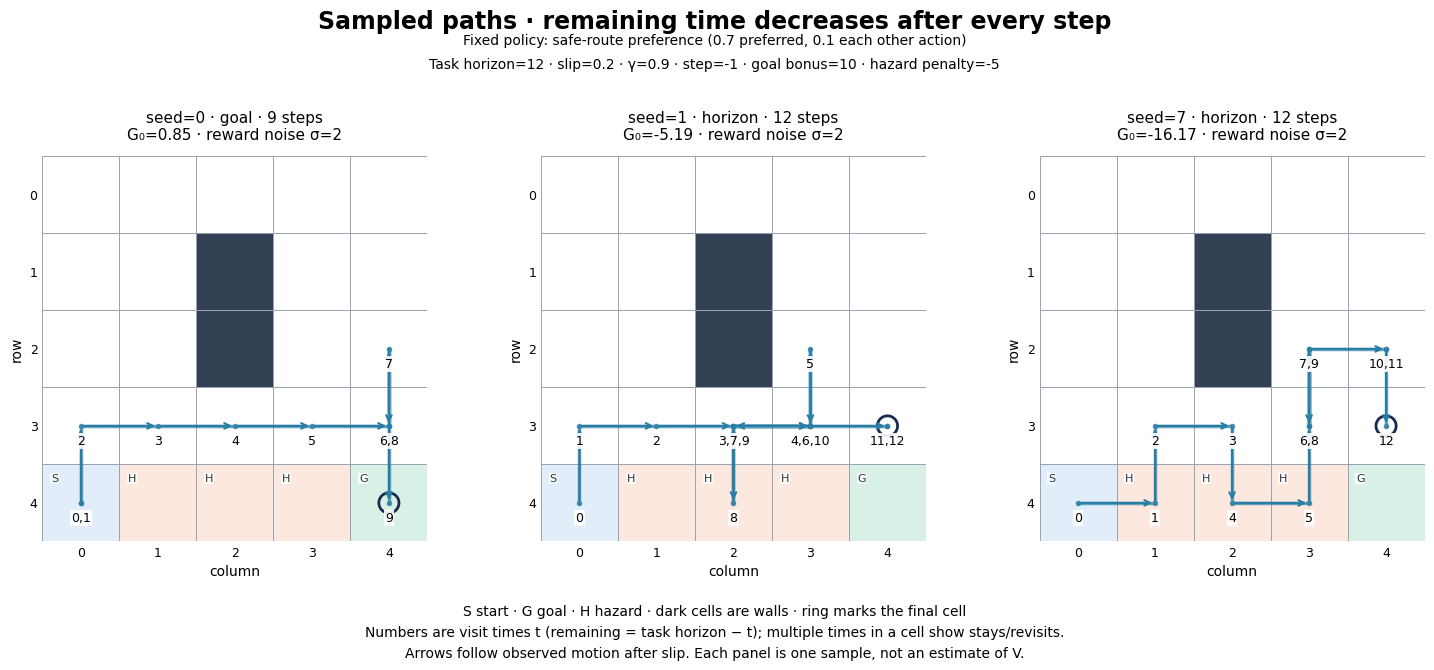

In [6]:
figure_episodes = [sample_episode(world, policy, seed=s, reward_noise_std=noise_std)
                   for s in FIGURE_SEEDS]
assert figure_episodes[-1] == episode
fig = plot_trajectories(world, figure_episodes, gamma=gamma, policy_name=POLICY_NAME)
display(fig)
plt.close(fig)

## Why noise changes variance, not the expected reward

The logits change action probabilities and thus which states are visited.
The environment supplies slip and reward noise. With this fixed state-only
policy, reward noise does not influence future actions or transitions.

Independence and zero mean give

$$\mathbb E[r_{t+1}\mid s_t,a_t,s_{t+1}]=\bar r(s_t,a_t,s_{t+1}),$$

so averaging over next states also preserves `world.expected_reward(s, a)`.
The added conditional reward variance is $\sigma^2$. Given a state/action path
of length $T$, the noise contribution to its discounted return has mean zero
and variance

$$\operatorname{Var}\!\left[\sum_{t=0}^{T-1}\gamma^t\epsilon_{t+1}\;\middle|\;
\mathrm{path}\right]=\sigma^2\sum_{t=0}^{T-1}\gamma^{2t}.$$

Unconditionally, expected return is also unchanged; the added return variance
averages this expression over paths. A particular noisy episode can have a
higher or lower return. It need not average to zero within that episode.

Changing only the noise scale keeps the same sampled path because its random
stream is separate. Compare the clean and noisy rewards on that path below.


In [7]:
clean = sample_episode(world, policy, seed=seed)
assert [(s.state, s.action, s.next_state) for s in clean.steps] == [
    (s.state, s.action, s.next_state) for s in episode.steps]
print(" t model reward   noise observed reward")
for base, noisy in zip(clean.steps, episode.steps):
    print(f"{base.t:2d} {base.reward:12.3f} {noisy.reward - base.reward:7.3f} {noisy.reward:15.3f}")
times = np.arange(len(episode.steps))
variance = noise_std**2 * np.sum(gamma**(2 * times))
print(f"Added return variance conditional on this path: {variance:.3f}")


 t model reward   noise observed reward
 0       -6.000   0.079          -5.921
 1       -1.000   2.216           1.216
 2       -1.000  -1.025          -2.025
 3       -6.000   1.746          -4.254
 4       -6.000   0.244          -5.756
 5       -1.000   2.383           1.383
 6       -1.000  -0.627          -1.627
 7       -1.000  -1.542          -2.542
 8       -1.000   0.582          -0.418
 9       -1.000   0.633          -0.367
10       -1.000  -1.187          -2.187
11       -1.000  -0.517          -1.517
Added return variance conditional on this path: 19.373


## Exact values by backward dynamic programming

A sampled $G_t$ is one return. The value $V^\pi(s)$ is its expectation under
the fixed policy. Since $s$ contains remaining time, the tables depend on both
cell and time; discounting starts at the state being evaluated:

$$Q^\pi(s,a)=\sum_{s'}P(s'\mid s,a)
  [\bar r(s,a,s')+\gamma V^\pi(s')],\qquad
V^\pi(s)=\sum_a\pi(a\mid s)Q^\pi(s,a),\qquad
A^\pi(s,a)=Q^\pi(s,a)-V^\pi(s).$$

`gridworld.values.evaluate_policy` starts with zero values at the goal and at
remaining time zero, then computes rows with 1, 2, ..., horizon steps left.
Every nonterminal successor has one fewer step left, so its value is already
available. The code's `torch.dot(probabilities, rewards + gamma * future_values)`
averages over model outcomes; `torch.dot(policy.probabilities(state), q[state])`
averages over actions. No samples or convergence loop are needed, even at
$\gamma=1$. All non-wall cell/time pairs are evaluated, including unreachable ones.

V, Q, advantage, and J are float64 tensors. `torch.stack` combines successor
values while retaining their graph; converting them to Python floats, NumPy,
or `torch.tensor(list_of_values)` inside this recurrence would break that path.
Fixed transition probabilities and mean rewards are constant tensors. We detach
only for display/sampling, and use `.item()` when a scalar is needed for a check.

For our deterministic start, $J(\theta)=V^{\pi_\theta}(s_0)$.
Independent zero-mean reward noise leaves this expectation unchanged.

### A two-step calculation you can check by hand

Use the one-row map `SHG`, no slip, horizon 2, $\gamma=0.5$, and
$\pi=(0.1,0.2,0.3,0.4)$ in north/east/south/west order at every nonterminal
state. An ordinary step pays $-1$, entering or staying on H pays $-6$, and
entering G pays $9$. Start with zero terminal values.

With one step left, $V(S,1)=0.8(-1)+0.2(-6)=-2$ and
$V(H,1)=0.4(-6)+0.2(9)+0.4(-1)=-1$.
With two steps left, an EAST action at S has
$Q(S,2,\mathrm{E})=-6+0.5V(H,1)=-6.5$;
the other actions stay at S, giving $-1+0.5V(S,1)=-2$.
Thus $J=V(S,2)=0.8(-2)+0.2(-6.5)=-2.9$.
The computed table below includes Q and advantage in the same action order.

In [8]:
tiny = Gridworld(layout=("SHG",), horizon=2, slip=0)
tiny_policy = TabularSoftmaxPolicy({
    s: torch.tensor([1., 2., 3., 4.], dtype=torch.float64).log() for s in tiny.states() if not tiny.is_terminal(s)
}, device=device)
tiny_values = evaluate_policy(tiny, tiny_policy, gamma=0.5)
print("cell left | Q(N,E,S,W)               | V     | A(N,E,S,W)")
for remaining in (1, 2):
    for cell, label in ((tiny.start, "S"), ((0, 1), "H")):
        state = State(cell, remaining)
        print(f"{label:>4} {remaining:4d} | {str(tiny_values.q[state].detach().cpu().numpy().round(2)):24s} | "
              f"{tiny_values.v[state]:5.2f} | {tiny_values.advantage[state].detach().cpu().numpy().round(2)}")
assert np.isclose(tiny_values.start_return.item(), -2.9)
assert all(tiny_values.v[s] == 0 for s in tiny.states() if tiny.is_terminal(s))
print(f"J = V(S,2) = {tiny_values.start_return:.2f}; all terminal V/Q/A rows are zero.")

cell left | Q(N,E,S,W)               | V     | A(N,E,S,W)
   S    1 | [-1. -6. -1. -1.]        | -2.00 | [ 1. -4.  1.  1.]
   H    1 | [-6.  9. -6. -1.]        | -1.00 | [-5. 10. -5.  0.]
   S    2 | [-2.  -6.5 -2.  -2. ]    | -2.90 | [ 0.9 -3.6  0.9  0.9]
   H    2 | [-6.5  9.  -6.5 -2. ]    | -1.60 | [-4.9 10.6 -4.9 -0.4]
J = V(S,2) = -2.90; all terminal V/Q/A rows are zero.


The policy-weighted advantage is zero because

$$\sum_a\pi(a\mid s)A^\pi(s,a)
=\sum_a\pi(a\mid s)Q^\pi(s,a)-V^\pi(s)\sum_a\pi(a\mid s)
=V^\pi(s)-V^\pi(s)=0.$$

At $(S,2)$, this is $0.8(0.9)+0.2(-3.6)=0$. The **unweighted** average
need not vanish. Positive advantage means better than the policy's average
choice at that state, even when Q itself is negative.

Replacing the policy average over next actions with a maximum chooses the
best continuation instead of following $\pi$. Applied throughout the backward
pass, that gives the Bellman optimality equation and a different policy's
return. Here even the current row's maximum Q, $-2$, differs from its
policy-weighted value, $-2.9$. We keep the policy fixed.

### Evaluate the earlier 5×5 policy

Now use the same manually chosen safe-route preferences, slip 0.2, horizon 12,
and $\gamma=0.9$ as the sampled episode. Each printed map fixes remaining time.
G has value zero because its entry reward was paid on the preceding transition;
the horizon-zero slice is also entirely zero. These are exact model
expectations, so a single noisy trajectory need not have return near J.

In [9]:
values = evaluate_policy(world, policy, gamma=gamma)
print(f"Expected start return J (gamma={gamma}): {values.start_return:.6f}")
for remaining in (1, world.horizon):
    print(f"\nV with {remaining} step(s) left:")
    for row, line in enumerate(world.layout):
        print(" ".join("    #  " if symbol == "#" else
                       f"{values.v[State((row, column), remaining)]:7.2f}"
                       for column, symbol in enumerate(line)))

nonterminal = [s for s in world.states() if not world.is_terminal(s)]
residual = max(abs(torch.dot(policy.probabilities(s), values.advantage[s]).item())
               for s in nonterminal)
assert residual < 1e-12
print(f"\nMax |sum_a pi(a|s) A(s,a)| over nonterminal rows: {residual:.2e}")

Expected start return J (gamma=0.9): -8.556035

V with 1 step(s) left:
  -1.00   -1.00   -1.00   -1.00   -1.00
  -1.00   -1.00     #     -1.00   -1.00
  -1.00   -1.00     #     -1.00   -1.00
  -1.00   -1.70   -1.70   -1.70    4.80
  -1.70   -2.40   -3.10   -1.00    0.00

V with 12 step(s) left:
  -6.50   -5.87   -4.74   -3.43   -2.19
  -7.11   -7.02     #     -1.86   -0.34
  -7.26   -7.16     #      0.09    2.35
  -7.10   -6.32   -3.41    0.76    5.94
  -8.56   -8.71   -7.07   -1.71    0.00

Max |sum_a pi(a|s) A(s,a)| over nonterminal rows: 1.39e-15


### Read V and the policy at a fixed remaining horizon

Each map fixes the **full state's remaining time**, and includes every non-wall
cell, even cells that cannot be reached from the start at that time. Row 0 is at
the top; coordinates match `State((row, column), remaining)`. Compare one step
left with twelve: the policy's chosen probabilities are the same at both times,
but V changes because different future rewards can still be collected.

The right panel prints **all four action probabilities**. Arrow size increases
with probability; these arrows show intended actions, while environmental slip
can send the agent elsewhere. No action is taken at G or at remaining time zero.
The left panel labels exact $V^\pi(s)=\sum_a\pi(a\mid s)Q^\pi(s,a)$ to two decimals.
The V color scale is local to each figure; use printed values to compare horizons.
Plotting detaches tensors only when copying numbers to the display; Bellman and
policy computations stay on CUDA.

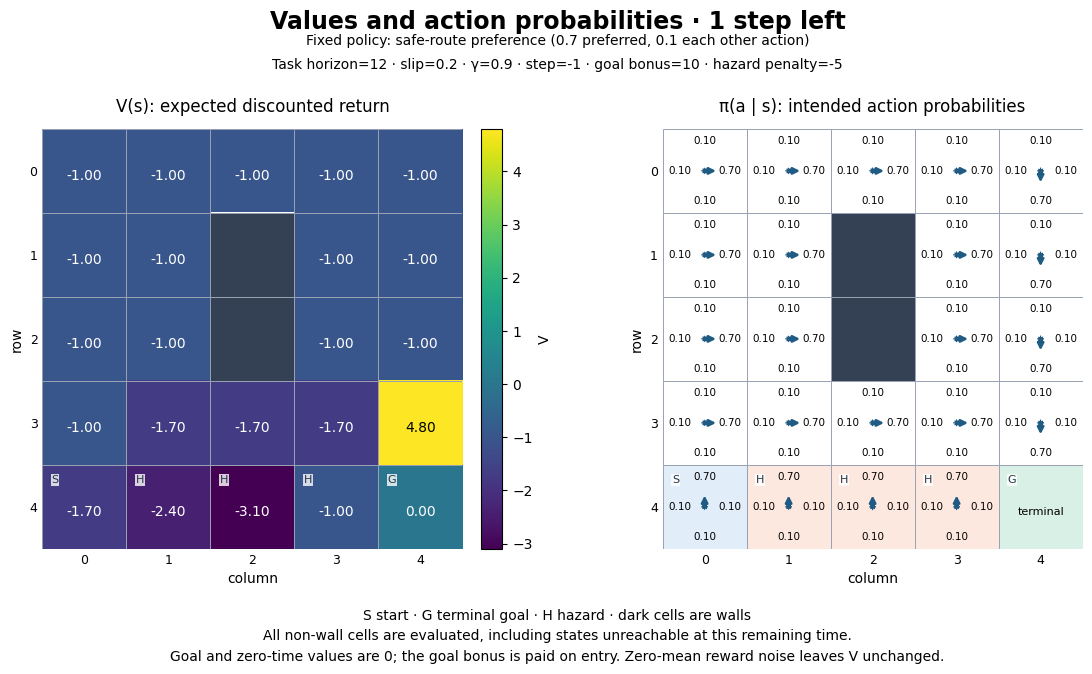

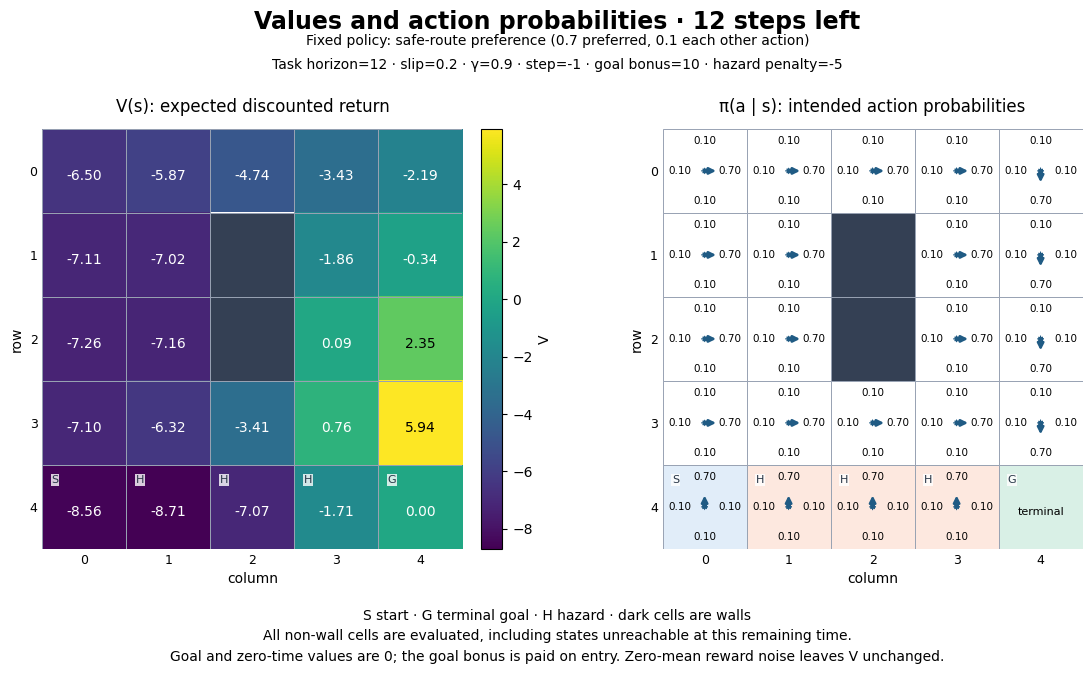

In [10]:
for remaining in (1, world.horizon):
    fig = plot_policy_values(world, policy, values, remaining=remaining,
                             gamma=gamma, policy_name=POLICY_NAME)
    display(fig)
    plt.close(fig)

### Action advantage is relative to the policy's average

The four panels share a symmetric scale centered at zero and use the exact
$A^\pi(s,a)=Q^\pi(s,a)-V^\pi(s)$ table. Positive (blue) means better than this
policy's average at the **same cell and remaining time**, even when V and Q are
negative. It does not imply a positive return or a guaranteed good sampled outcome.
The values average over both policy actions and slip; independent zero-mean
reward noise leaves these expectations unchanged.

For the earlier two-step `SHG` example at $(S,2)$,
$V=-2.9$, $Q(\mathrm{NORTH})=-2$, and
$A(\mathrm{NORTH})=-2-(-2.9)=+0.9$. Thus **an action can have positive advantage
in a state with negative value**. EAST has $A=-3.6$, and the policy-weighted
average is $0.8(0.9)+0.2(-3.6)=0$; an unweighted average need not be zero.
The table below connects selected 5×5 map cells to their full-precision evaluator
rows. The plotted numbers are the same values rounded to two decimals.

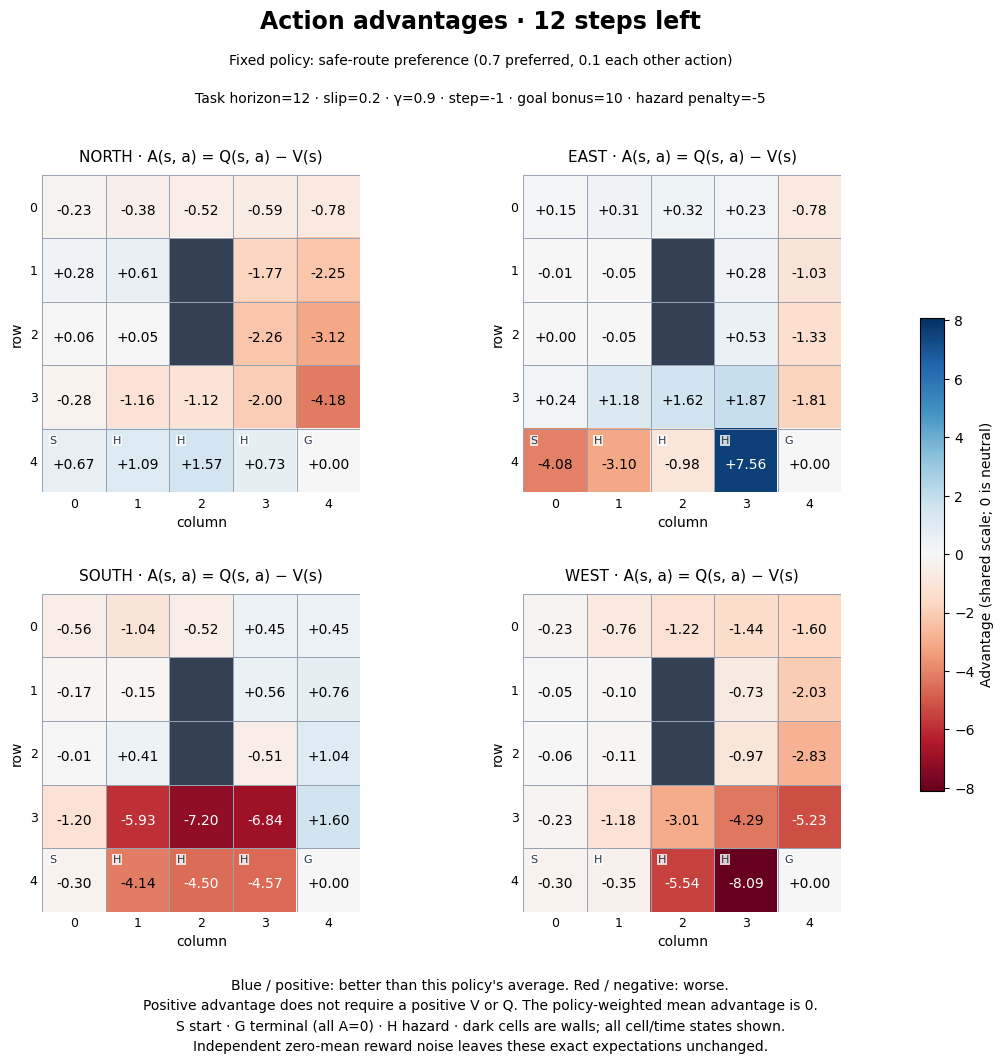

cell  left | V        | pi(N,E,S,W)       | Q(N,E,S,W)                    | A(N,E,S,W)
(4, 0)    1 |  -1.7000 | [0.7 0.1 0.1 0.1] | [-1.3333 -5.     -1.3333 -1.3333] | [ 0.3667 -3.3     0.3667  0.3667]
(4, 0)   12 |  -8.5560 | [0.7 0.1 0.1 0.1] | [ -7.8882 -12.6391  -8.8518  -8.8518] | [ 0.6678 -4.083  -0.2958 -0.2958]
(3, 3)   12 |   0.7619 | [0.1 0.7 0.1 0.1] | [-1.2347  2.6362 -6.0761 -3.5235] | [-1.9967  1.8743 -6.838  -4.2855]
SHG, S with 2 steps left: V=-2.9, Q(NORTH)=-2.0, A(NORTH)=+0.9.


In [11]:
fig = plot_advantages(world, values, remaining=world.horizon,
                      gamma=gamma, policy_name=POLICY_NAME)
display(fig)
plt.close(fig)
print("cell  left | V        | pi(N,E,S,W)       | Q(N,E,S,W)                    | A(N,E,S,W)")
for state in (State(world.start, 1), world.start_state, State((3, 3), world.horizon)):
    pi = policy.probabilities(state).detach().cpu().numpy()
    q = values.q[state].detach().cpu().numpy()
    a = values.advantage[state].detach().cpu().numpy()
    v = values.v[state].item()
    np.testing.assert_allclose(a, q - v, rtol=1e-12, atol=1e-12)
    assert abs(np.dot(pi, a)) < 1e-12
    print(f"{state.cell} {state.remaining:4d} | {v:8.4f} | {pi.round(2)} | {q.round(4)} | {a.round(4)}")
hand_state = State(tiny.start, 2)
assert tiny_values.v[hand_state].item() < 0 < tiny_values.advantage[hand_state][0].item()
print("SHG, S with 2 steps left: V=-2.9, Q(NORTH)=-2.0, A(NORTH)=+0.9.")

### Reproduce and save the selected figures

From `rl_math`, run the following without a notebook or browser:

```bash
uv sync --locked
uv run --locked python -m gridworld.figures --output-dir runs/gridworld-figures --device cuda
```

This uses the same model, fixed policy, $\gamma=0.9$, noise $\sigma=2$, and seed
list. It saves the paths, both value/policy slices, the horizon-12 advantage map,
and `manifest.json` with settings, versions, selected exact rows, sampled data,
and runtime. **Choose a new output directory for each run**; the command refuses
to overwrite an existing directory. Notebook display itself writes no figure
files. The committed examples are in `figures/gridworld/`. `--device cpu` is
available for the independent reference path; the notebook and default figure
command use CUDA. No training or policy update is involved.

## Differentiate the exact expected return with PyTorch

Knowing the model lets us differentiate $J(\theta)=V^{\pi_\theta}(s_0)$ itself.
The evaluator has already built the graph
**logits → softmax probabilities → Bellman expectations → J**.
`gridworld.gradients.differentiate_policy` evaluates J, then calls
[`torch.autograd.grad`](https://docs.pytorch.org/docs/stable/generated/torch.autograd.grad.html)
on it and all the logit parameters. PyTorch applies the chain rule through the
whole graph; we do not implement a separate backward algorithm.

`materialize_grads=True` returns zeros for rows disconnected from J, including
optional terminal rows. `autograd.grad` returns derivatives without accumulating
the parameters' `.grad` buffers or updating them. The returned `PolicyGradient`
contains `values` and `gradient`, a detached tensor for each supplied logit row.

For interpretation, the local softmax derivative is still

$$\frac{\partial\pi(a\mid s)}{\partial\theta_{s,b}}
=\pi(a\mid s)\bigl(\mathbf 1[a=b]-\pi(b\mid s)\bigr).$$

Combining this with the Bellman expectations gives

$$\frac{\partial J}{\partial\theta_{s,b}}
=\gamma^t\Pr(s_t=s)\,\pi(b\mid s)\,A(s,b),
\qquad t=H-\mathrm{remaining}.$$

Each cell/remaining-time row has independent parameters. The local Q/advantage
discounts rewards relative to that state; the outer $\gamma^t$ discounts back
to the episode start. Autograd obtains both from the same gamma factors in the
value computation, including dependencies through successor values. We do not
normalize by episode length or total occupancy.


### Continue the two-step `SHG` example

Keep $\gamma=0.5$, no slip, and $\pi=(0.1,0.2,0.3,0.4)$ in each row.
At $t=0$ we are at $(S,2)$ with weight 1. At $t=1$, the state is $(S,1)$
with probability 0.8 or $(H,1)$ with probability 0.2. Their reverse weights are
$0.5(0.8)=0.4$ and $0.5(0.2)=0.1$.

For example, the EAST derivative at the start is
$1(0.2)(-3.6)=-0.72$. At $(H,1)$ it is
$0.1(0.2)(10)=0.20$: the goal reward matters only on paths visiting that row,
and its effect on J is discounted once. The complete gradient rows are below.
$(H,2)$ has nonzero local action advantages but is unreachable from the start,
so all its derivatives of J are zero.


In [12]:
reference = differentiate_policy(tiny, tiny_policy, gamma=0.5)
assert reference.values.start_return.item() == tiny_values.start_return.item()
print(f"Exact J = {reference.values.start_return.item():.2f}")
print("cell left | dJ/dlogits (N,E,S,W)")
for cell, label, remaining in ((tiny.start, "S", 2), (tiny.start, "S", 1),
                               ((0, 1), "H", 1), ((0, 1), "H", 2)):
    state = State(cell, remaining)
    print(f"{label:>4} {remaining:4d} | {reference.gradient[state].cpu().numpy().round(4)}")
torch.testing.assert_close(reference.gradient[State((0, 1), 1)],
                           reference.gradient[State((0, 1), 1)].new_tensor([-.05, .2, -.15, 0]),
                           rtol=1e-12, atol=1e-14)


Exact J = -2.90
cell left | dJ/dlogits (N,E,S,W)
   S    2 | [ 0.09 -0.72  0.27  0.36]
   S    1 | [ 0.04 -0.32  0.12  0.16]
   H    1 | [-0.05  0.2  -0.15  0.  ]
   H    2 | [0. 0. 0. 0.]


### Check every logit with central finite differences

For a single parameter $\theta_{s,b}$, change only that entry and call the
previous value evaluator twice:

$$D_{s,b}(\epsilon)=\frac{J(\theta+\epsilon e_{s,b})
-J(\theta-\epsilon e_{s,b})}{2\epsilon}.$$

This check differentiates the scalar return numerically without using the
autograd result. Use $\epsilon=10^{-5}$ in float64, with absolute tolerance
$10^{-8}$ plus relative tolerance $10^{-6}$ (`torch.testing.assert_close`).
The absolute term covers derivatives near zero. Central differences have
$O(\epsilon^2)$ truncation error for this smooth objective; very small steps can
instead magnify floating-point cancellation. These settings apply to this tiny,
moderately scaled example, rather than every possible logit/reward scale.

We perturb all 16 independent logits, including unreachable rows, in the `SHG`
model. Its step costs and hazard penalties give nontrivial rewards before the
last transition. Omitting the outer discount would double the nonzero $t=1$
derivatives and fail this check. Detach and clone each row to leave `tiny_policy` fixed. We use
`torch.no_grad()` for these scalar-only evaluations; the reference computation
above needs its graph enabled.


In [13]:
epsilon = 1e-5
numerical = {s: torch.zeros_like(row) for s, row in tiny_policy.logits.items()}
with torch.no_grad():
    for state in numerical:
        for b in range(len(Action)):
            returns = []
            for sign in (1, -1):
                perturbed = {s: row.detach().clone() for s, row in tiny_policy.logits.items()}
                perturbed[state][b] += sign * epsilon
                returns.append(evaluate_policy(
                    tiny, TabularSoftmaxPolicy(perturbed, device=device), gamma=0.5
                ).start_return.item())
            numerical[state][b] = (returns[0] - returns[1]) / (2 * epsilon)

print("cell left | max |autograd - finite difference|")
for state in numerical:
    error = (reference.gradient[state] - numerical[state]).abs().max().item()
    print(f"{str(state.cell):>6} {state.remaining:4d} | {error:.3e}")
    torch.testing.assert_close(reference.gradient[state], numerical[state],
                               rtol=1e-6, atol=1e-8)
print("All 16 logit derivatives agree (epsilon=1e-5, rtol=1e-6, atol=1e-8).")


cell left | max |autograd - finite difference|
(0, 0)    1 | 2.566e-11
(0, 1)    1 | 2.097e-11
(0, 0)    2 | 4.591e-11
(0, 1)    2 | 0.000e+00
All 16 logit derivatives agree (epsilon=1e-5, rtol=1e-6, atol=1e-8).


### The exact reference for the earlier 5×5 policy

Now differentiate the same horizon-12, slip-0.2 policy at $\gamma=0.9$.
The returned J must agree with the earlier value evaluation. Each gradient row
sums to zero: adding a constant to every logit in one row changes no probabilities
and hence no return. The norm below is over all independent cell/time logits.

These are derivatives at the fixed policy, before any optimizer step. Independent
zero-mean reward noise changes neither the conditional reward means nor this
gradient, so it can later vary sampling variance while the reference stays fixed.
The unit tests also compare every derivative on a tiny **stochastic** model with
time-dependent logits and $\gamma\in\{0,0.7,1\}$, check early goal termination,
and verify constant-logit-shift invariance.


In [14]:
gradient_reference = differentiate_policy(world, policy, gamma=gamma)
assert gradient_reference.values.start_return.item() == values.start_return.item()
rows = torch.stack(list(gradient_reference.gradient.values()))
residual = rows.sum(dim=1).abs().max().item()
assert residual < 1e-12
print(f"Exact J: {gradient_reference.values.start_return.item():.6f}")
print("Start logit gradient (N,E,S,W):",
      gradient_reference.gradient[world.start_state].cpu().numpy().round(6))
print(f"Gradient L2 norm over {rows.numel()} logits: {torch.linalg.vector_norm(rows).item():.6f}")
print(f"Max |sum of logit derivatives in one row|: {residual:.2e}")


Exact J: -8.556035
Start logit gradient (N,E,S,W): [ 0.467465 -0.408304 -0.02958  -0.02958 ]


Gradient L2 norm over 1056 logits: 0.908393
Max |sum of logit derivatives in one row|: 2.22e-16


## Full-return REINFORCE: one sampled gradient

The exact reference differentiates a sum over possible futures. We can instead
use the probability of a **sampled complete trajectory**. With environment
transitions and reward noise independent of the policy parameters,

$$\nabla_\theta\log p_\theta(\tau)
=\sum_{t=0}^{T-1}\nabla_\theta\log\pi_\theta(a_t\mid s_t).$$

The log-derivative identity gives, for our discounted start-state objective,

$$J(\theta)=\mathbb E[G_0],\qquad G_0=\sum_{k=0}^{T-1}\gamma^k r_{k+1},$$
$$\nabla_\theta J
=\mathbb E\!\left[G_0\sum_{t=0}^{T-1}\nabla_\theta\log\pi_\theta(a_t\mid s_t)\right].$$

Every action gets the **same full return $G_0$** because we differentiate the
probability of the entire trajectory and multiply by its scalar return.
The discounting is already inside $G_0$: multiplying these score terms by an
additional $\gamma^t$ would change the expected gradient. The earlier
`reward_to_go_weights` helper uses a different signal, $\gamma^t G_t$.

For a tabular softmax row, the score is

$$\frac{\partial\log\pi(a\mid s)}{\partial\theta_{s,b}}
=\mathbf 1[a=b]-\pi(b\mid s).$$

Other rows have zero derivative for this action. PyTorch computes this with
`autograd.grad` through `log_softmax`; we use the formula only to check it by hand.
[Spinning Up derives the trajectory score identity](https://spinningup.openai.com/en/latest/spinningup/rl_intro3.html#deriving-the-simplest-policy-gradient)
for an undiscounted return; here we substitute our finite discounted $G_0$.


### Hand-worked trajectory: EAST, then EAST

Continue the `SHG` example, with $\gamma=0.5$ and
$\pi=(0.1,0.2,0.3,0.4)$. The trajectory S → H → G pays $(-6,9)$,
so $G_0=-6+0.5(9)=-1.5$. Its probability is $0.2^2=0.04$.
Both actions have score $(-0.1,0.8,-0.3,-0.4)$ in their own row:

| Parameter row | Score contribution | $G_0$ × score |
| --- | --- | --- |
| $(S,2)$ | $(-0.1,0.8,-0.3,-0.4)$ | $(0.15,-1.2,0.45,0.6)$ |
| $(H,1)$ | $(-0.1,0.8,-0.3,-0.4)$ | $(0.15,-1.2,0.45,0.6)$ |
| Unvisited rows | $(0,0,0,0)$ | $(0,0,0,0)$ |

This **single** trajectory penalizes EAST at H even though EAST immediately
reaches the goal there. Its earlier hazard penalty is included in the shared
return. That irrelevant past reward has zero expected score contribution at H,
but varies across samples and adds noise to its gradient. Independent reward
noise also enters $G_0$ and weights every action score. These observations
motivate later estimators; this bead keeps the full-return signal.


In [15]:
parameters = tuple(tiny_policy.logits.values())
hand_states = [tiny.start_state, State((0, 1), 1)]
score, = torch.autograd.grad(tiny_policy.log_probabilities(hand_states[0])[1],
                            (tiny_policy.logits[hand_states[0]],))
print("EAST score at S,2:", score.cpu().numpy().round(3))
hand_logp = torch.stack([tiny_policy.log_probabilities(s)[1] for s in hand_states])
hand_gradient = dict(zip(tiny_policy.logits, full_return_gradient(hand_logp, [-6., 9.], parameters, gamma=.5)))
for state in hand_states:
    print(f"{state}: {hand_gradient[state].cpu().numpy().round(3)}")
    torch.testing.assert_close(hand_gradient[state], score.new_tensor([.15, -1.2, .45, .6]),
                               rtol=1e-12, atol=1e-14)


EAST score at S,2: [-0.1  0.8 -0.3 -0.4]
State(cell=(0, 0), remaining=2): [ 0.15 -1.2   0.45  0.6 ]
State(cell=(0, 1), remaining=1): [ 0.15 -1.2   0.45  0.6 ]


### Average whole episode sums, then check the exact expectation

`algorithms.reinforce.full_return_gradient` accepts a complete episode's 1D tensor
of selected action log-probabilities, recorded rewards, and the parameters to
differentiate. Log-probabilities retain their graph under the **same frozen
policy that collected the episode**. The algorithm needs no environment types
or additional episode record.

It differentiates the scalar surrogate for one episode,

$$L_\tau(\theta)=G_0\underbrace{\sum_t\log\pi_\theta(a_t\mid s_t)}_{\text{episode sum}},$$

holding recorded rewards fixed. This returns the **ascent** gradient, in parameter
order, without changing logits or their `.grad` buffers. $L_\tau$ is a device for
obtaining the gradient, not an estimate of J. Average the returned gradient sums
over episode count $N$, including for unequal lengths; averaging flattened
transitions would instead divide by the number of actions.

`Episode.rewards()` extracts the recorded rewards in order.
`Episode.log_probabilities(policy.log_probabilities)` evaluates each recorded
state and selects its recorded action from the returned row. Passing the
function keeps the policy separate from the trajectory. Each call creates a
fresh autograd graph; the episode stores only sampled data. There is no
optimizer step.

Our no-slip, horizon-2 `SHG` model has exactly $4^2=16$ action sequences.
Enumerate each complete path, compute its probability and sampled gradient,
then sum **probability × gradient**. This deterministic check must recover the
previous Bellman/autograd reference in every parameter row.


In [16]:
from itertools import product

expected_rows = torch.zeros((len(parameters), 4), dtype=torch.float64, device=device)
probability_mass = 0.
for actions in product(Action, repeat=2):
    state, path_probability = tiny.start_state, 1.
    selected_logp, rewards = [], []
    for action in actions:
        index = tuple(Action).index(action)
        path_probability *= tiny_policy.probabilities(state)[index].item()
        selected_logp.append(tiny_policy.log_probabilities(state)[index])
        outcome, = tiny.transitions(state, action)  # This model has no slip.
        rewards.append(outcome.reward)
        state = outcome.next_state
    assert tiny.is_terminal(state)
    path_gradient = torch.stack(full_return_gradient(torch.stack(selected_logp), rewards, parameters, gamma=.5))
    expected_rows += path_probability * path_gradient
    probability_mass += path_probability

exact_rows = torch.stack([reference.gradient[s] for s in tiny_policy.logits])
assert np.isclose(probability_mass, 1.)
torch.testing.assert_close(expected_rows, exact_rows, rtol=1e-12, atol=1e-14)
print(f"16 paths; probability mass = {probability_mass:.12f}")
print(f"Max |expected REINFORCE - exact gradient| = {(expected_rows - exact_rows).abs().max().item():.2e}")
print("Expected start gradient:", expected_rows[list(tiny_policy.logits).index(tiny.start_state)].cpu().numpy().round(4))


16 paths; probability mass = 1.000000000000
Max |expected REINFORCE - exact gradient| = 1.67e-16
Expected start gradient: [ 0.09 -0.72  0.27  0.36]


### One short seeded sample at the frozen policy

Collect **256 episodes**, seeds **0 through 255**, in that same two-step `SHG`
model, with no slip, $\gamma=0.5$, and independent reward-noise standard
deviation **2.0**. There are 512 environment transitions. This is one batch,
with no training or parameter updates. Log-probabilities and gradient tensors
stay on CUDA; only NumPy sampling and printed values cross to CPU.

Compute each episode's gradient once, then use those gradients to calculate
both the sample mean and its standard error. The sampled mean need not equal
the reference. The standard error measures variation in this small sample; it is
not an exact error bound or a guarantee that increasing sample count improves
every realized estimate. The enumeration above establishes agreement in
expectation. This sample illustrates finite-data noise and is not a variance
comparison between estimators.


In [17]:
from time import perf_counter

started = perf_counter()
frozen_logits = {s: row.detach().clone() for s, row in tiny_policy.logits.items()}
seeds, sample_sigma, sample_gamma = list(range(256)), 2., .5
samples = [sample_episode(tiny, tiny_policy, seed=s, reward_noise_std=sample_sigma) for s in seeds]
# Evaluate selected action log-probabilities under the unchanged collecting policy.
episode_gradients = torch.stack([
    torch.stack(full_return_gradient(
        sampled.log_probabilities(tiny_policy.log_probabilities),
        sampled.rewards(), parameters, gamma=sample_gamma,
    )) for sampled in samples
])
sample_mean = episode_gradients.mean(dim=0)
standard_error = episode_gradients.std(dim=0, correction=1) / np.sqrt(len(samples))
start_index = list(tiny_policy.logits).index(tiny.start_state)
print(f"N={len(samples)}, seeds=0..255, transitions={sum(len(e.steps) for e in samples)}, sigma={sample_sigma}")
print("Start row (N,E,S,W):")
print("  exact:    ", exact_rows[start_index].cpu().numpy().round(4))
print("  estimate: ", sample_mean[start_index].cpu().numpy().round(4))
print("  std error:", standard_error[start_index].cpu().numpy().round(4))
print(f"L2 error over all logits: {torch.linalg.vector_norm(sample_mean - exact_rows).item():.4f}")
for state, row in tiny_policy.logits.items():
    torch.testing.assert_close(row, frozen_logits[state], rtol=0, atol=0)
    assert row.grad is None
assert sample_mean.device.type == "cuda"
print(f"Elapsed (collection + episode derivatives): {perf_counter() - started:.3f} s")
print("Policy unchanged; no gradients accumulated; no parameter updates.")


N=256, seeds=0..255, transitions=512, sigma=2.0
Start row (N,E,S,W):
  exact:     [ 0.09 -0.72  0.27  0.36]
  estimate:  [ 0.0014 -0.5436  0.2788  0.2635]
  std error: [0.0705 0.155  0.1037 0.1211]
L2 error over all logits: 0.3922
Elapsed (collection + episode derivatives): 0.163 s
Policy unchanged; no gradients accumulated; no parameter updates.


## Reward-to-go: an action cannot change rewards already received

For the same discounted start-state objective, split the full return at action $t$:

$$G_0=\underbrace{\sum_{k=0}^{t-1}\gamma^k r_{k+1}}_{C_t\text{: past discounted rewards}}
+\gamma^t\underbrace{\sum_{k=t}^{T-1}\gamma^{k-t}r_{k+1}}_{G_t\text{: reward-to-go}}.$$

Let $\mathcal H_t$ be the history **before** sampling $a_t$, including $s_t$ and
all rewards already received. Conditioned on this history, $C_t$ is fixed and
the current action is drawn from $\pi_\theta(\cdot\mid s_t)$. Its expected score is

$$\mathbb E[\nabla_\theta\log\pi_\theta(a_t\mid s_t)\mid\mathcal H_t]
=\sum_a\pi_\theta(a\mid s_t)\nabla_\theta\log\pi_\theta(a\mid s_t)
=\nabla_\theta\sum_a\pi_\theta(a\mid s_t)=0.$$

Therefore $\mathbb E[C_t\nabla\log\pi(a_t\mid s_t)]=0$ after averaging over
histories too. This is a conditional argument: past rewards and the current
state can be correlated. The discarded contribution is generally **nonzero in
an individual trajectory**, which is why the sampled gradients change.

The same expected gradient can thus be estimated with

$$\widehat g_{\rm RTG}(\tau)
=\sum_{t=0}^{T-1}\gamma^tG_t\nabla_\theta\log\pi_\theta(a_t\mid s_t).$$

The inner discount in $G_t$ starts at action $t$; the **outer $\gamma^t$** places
that return back at episode start. Omitting it changes the objective when
$\gamma<1$. `common.returns.reward_to_go_weights` already computes these weights.
`algorithms.reinforce.reward_to_go_gradient` copies them to the log-probability
device and differentiates `torch.dot(weights, log_probabilities)`. Recorded
rewards are constants. As before, this scalar is a gradient surrogate, and we
average whole episode sums. Use a fresh log-probability graph for each estimator
under the unchanged collecting policy; each autograd call consumes its graph.


### The same EAST, EAST trajectory gets different credit

Keep the no-slip, horizon-2 `SHG` model, $\gamma=0.5$, and
$\pi=(0.1,0.2,0.3,0.4)$. The path S → H → G gives rewards $(-6,9)$.
The first action still gets $G_0=-1.5$. For the second action, $G_1=9$, so its
reward-to-go weight is $\gamma G_1=4.5$. The earlier $-6$ hazard cost no longer
weights that later action's score. Both visited rows have EAST score
$(-0.1,0.8,-0.3,-0.4)$.

| Parameter row | Full-return weight | Reward-to-go weight | Reward-to-go gradient row |
| --- | --- | --- | --- |
| $(S,2)$ | $-1.5$ | $-1.5$ | $(0.15,-1.2,0.45,0.6)$ |
| $(H,1)$ | $-1.5$ | $4.5$ | $(-0.45,3.6,-1.35,-1.8)$ |

EAST at H receives opposite signs in these two estimates of the **same** gradient.
Neither single trajectory is the exact gradient; equality holds in expectation.
At $\gamma=1$ the reward-to-go weights would be $(3,9)$ versus full-return
weights $(3,3)$. At $\gamma=0$ only the first reward matters to J, and the
reward-to-go weight for the later action is zero. Tests cover all three cases.


In [18]:
from algorithms.reinforce import reward_to_go_gradient
from common.returns import reward_to_go_weights

rtg_hand_logp = torch.stack([tiny_policy.log_probabilities(s)[1] for s in hand_states])
rtg_hand_gradient = dict(zip(tiny_policy.logits, reward_to_go_gradient(
    rtg_hand_logp, [-6., 9.], parameters, gamma=.5,
)))
print("Reward-to-go weights:", reward_to_go_weights([-6., 9.], gamma=.5))
print("cell  left | full-return gradient          | reward-to-go gradient (N,E,S,W)")
for state, expected in zip(hand_states, ([.15, -1.2, .45, .6], [-.45, 3.6, -1.35, -1.8])):
    print(f"{state.cell} {state.remaining:4d} | {hand_gradient[state].cpu().numpy().round(3)} | "
          f"{rtg_hand_gradient[state].cpu().numpy().round(3)}")
    torch.testing.assert_close(rtg_hand_gradient[state], score.new_tensor(expected),
                               rtol=1e-12, atol=1e-14)


Reward-to-go weights: [-1.5, 4.5]
cell  left | full-return gradient          | reward-to-go gradient (N,E,S,W)
(0, 0)    2 | [ 0.15 -1.2   0.45  0.6 ] | [ 0.15 -1.2   0.45  0.6 ]
(0, 1)    1 | [ 0.15 -1.2   0.45  0.6 ] | [-0.45  3.6  -1.35 -1.8 ]


### Check both expectations against the exact gradient

Enumerate the same 16 complete action paths, now for **both estimators** and
$\gamma\in\{0.5,1\}$. Weight each path's gradient by its exact probability.
The model has no slip or reward noise for this deterministic expectation check;
the policy remains stochastic. Compare every parameter row with the existing
Bellman/autograd reference, including unvisited or unreachable rows.

The tests additionally enumerate stochastic transitions and early goal endings,
with $\gamma\in\{0,0.5,1\}$, and check shared parameters and unequal episode lengths.


In [19]:
# Record the tiny model's complete paths once, without retaining policy graphs.
exact_paths = []
for actions in product(Action, repeat=2):
    path_state, path_probability = tiny.start_state, 1.
    path_states, action_indices, path_rewards = [], [], []
    for action in actions:
        index = tuple(Action).index(action)
        path_probability *= tiny_policy.probabilities(path_state)[index].item()
        path_states.append(path_state)
        action_indices.append(index)
        outcome, = tiny.transitions(path_state, action)
        path_rewards.append(outcome.reward)
        path_state = outcome.next_state
    assert tiny.is_terminal(path_state)
    exact_paths.append((path_probability, path_states, action_indices, path_rewards))
assert np.isclose(sum(p for p, *_ in exact_paths), 1.)

for discount in (.5, 1.):
    exact = differentiate_policy(tiny, tiny_policy, gamma=discount)
    exact_matrix = torch.stack([exact.gradient[s] for s in tiny_policy.logits])
    for estimator in (full_return_gradient, reward_to_go_gradient):
        expected = torch.zeros_like(exact_matrix)
        for probability, path_states, action_indices, path_rewards in exact_paths:
            # Each estimator needs a fresh graph, even on the same recorded path.
            logp = torch.stack([tiny_policy.log_probabilities(s)[a]
                               for s, a in zip(path_states, action_indices)])
            expected += probability * torch.stack(estimator(logp, path_rewards, parameters, gamma=discount))
        torch.testing.assert_close(expected, exact_matrix, rtol=1e-12, atol=1e-14)
        print(f"gamma={discount:.1f} {estimator.__name__:24s}: "
              f"max |expected - exact| = {(expected - exact_matrix).abs().max().item():.2e}")


gamma=0.5 full_return_gradient    : max |expected - exact| = 1.67e-16


gamma=0.5 reward_to_go_gradient   : max |expected - exact| = 1.67e-16
gamma=1.0 full_return_gradient    : max |expected - exact| = 2.22e-16
gamma=1.0 reward_to_go_gradient   : max |expected - exact| = 2.22e-16


### Why terminal rewards alone hide this comparison

If the only nonzero reward is $r_T$, then for **every** action in that episode,

$$\gamma^tG_t=\gamma^t\gamma^{T-1-t}r_T=\gamma^{T-1}r_T=G_0.$$

Full return and correctly discounted reward-to-go then give the **same sampled
gradient**, even before averaging and even if episode lengths vary. To see the
effect of removing past rewards, we need intermediate rewards such as this
model's step costs and hazard penalties. Independent reward noise at earlier
steps also creates intermediate observed rewards. The unit tests verify
sample-wise equality on terminal-reward-only sequences.


### Reuse the same short seeded batch

Apply reward-to-go to the **same 256 complete episodes** already collected
above: seeds 0..255, the fixed `SHG` policy, horizon 2, no slip, $\gamma=0.5$,
and reward-noise standard deviation 2.0. There are still only **512 collected
transitions**. Reusing these samples is valid because the policy has not changed.

The start-row samples agree because the first weight is $G_0$ in both methods.
The table examines $(H,1)$, where past rewards can be discarded. Average over
**all 256 episodes**, including the zero gradient from paths that never visit
that row. Averaging only visiting episodes would estimate a different quantity.
Each standard error describes variation in this small batch. This is a paired
illustration, not a broad variance study or a guarantee that every coordinate
or finite batch improves. The exact enumeration establishes unbiasedness.


In [20]:
rtg_started = perf_counter()
rtg_episode_gradients = torch.stack([
    torch.stack(reward_to_go_gradient(
        sampled.log_probabilities(tiny_policy.log_probabilities),
        sampled.rewards(), parameters, gamma=sample_gamma,
    )) for sampled in samples
])
torch.testing.assert_close(rtg_episode_gradients[:, start_index], episode_gradients[:, start_index],
                           rtol=1e-12, atol=1e-14)
late_index = list(tiny_policy.logits).index(State((0, 1), 1))
rtg_mean = rtg_episode_gradients.mean(dim=0)
rtg_se = rtg_episode_gradients.std(dim=0, correction=1) / np.sqrt(len(samples))
print(f"N={len(samples)}, reused seeds=0..255, transitions=512, gamma={sample_gamma}, sigma={sample_sigma}")
print("H with 1 step left (N,E,S,W):")
print("  exact:       ", exact_rows[late_index].cpu().numpy().round(4))
print("  full return: ", sample_mean[late_index].cpu().numpy().round(4))
print("  full SE:     ", standard_error[late_index].cpu().numpy().round(4))
print("  reward-to-go:", rtg_mean[late_index].cpu().numpy().round(4))
print("  RTG SE:      ", rtg_se[late_index].cpu().numpy().round(4))
print("Start-row samples agree; later-row samples differ.")
assert (rtg_episode_gradients[:, late_index] - episode_gradients[:, late_index]).abs().max().item() > 0
for state, row in tiny_policy.logits.items():
    torch.testing.assert_close(row, frozen_logits[state], rtol=0, atol=0)
    assert row.grad is None
assert rtg_mean.device.type == "cuda"
print(f"Elapsed (reward-to-go derivatives only): {perf_counter() - rtg_started:.3f} s")
print("Policy unchanged; no baseline, normalization, or parameter updates.")


N=256, reused seeds=0..255, transitions=512, gamma=0.5, sigma=2.0
H with 1 step left (N,E,S,W):
  exact:        [-0.05  0.2  -0.15  0.  ]
  full return:  [-0.0295  0.1987 -0.1765  0.0073]
  full SE:      [0.0652 0.0406 0.1059 0.0912]
  reward-to-go: [-0.0326  0.1566 -0.1245  0.0005]
  RTG SE:       [0.0201 0.0433 0.0342 0.0302]
Start-row samples agree; later-row samples differ.
Elapsed (reward-to-go derivatives only): 0.105 s
Policy unchanged; no baseline, normalization, or parameter updates.


In this fixed batch, the estimated standard error at H falls for NORTH, SOUTH,
and WEST, but rises slightly for EAST (0.0406 to 0.0433). The EAST mean is
also farther from the exact 0.2 in the reward-to-go sample. Removing past
rewards preserves the expectation; it does not guarantee that every finite
sample or every coordinate gets closer to the exact gradient.


## A state baseline changes the samples, not the expected gradient

Fix a function $b(s)$ before collecting the probe episodes. It must not depend
on the action sampled at $s$ or the subsequent returns. Our full state includes
remaining time, so the same cell can have different baselines at different times.
Conditioning on the history before $a_t$, $b(s_t)$ is a constant:

$$\mathbb E[b(s_t)\nabla_\theta\log\pi_\theta(a_t\mid s_t)\mid\mathcal H_t]
=b(s_t)\sum_a\pi_\theta(a\mid s_t)\nabla_\theta\log\pi_\theta(a\mid s_t)
=b(s_t)\nabla_\theta 1=0.$$

Thus we can use

$$\widehat g_b(\tau)=\sum_{t=0}^{T-1}\gamma^t
\bigl(G_t-b(s_t)\bigr)\nabla_\theta\log\pi_\theta(a_t\mid s_t),
\qquad \mathbb E[\widehat g_b]=\nabla_\theta J.$$

The outer $\gamma^t$ multiplies **both** terms. Cancellation needs no accurate
value prediction: a deliberately imperfect state-only function also works.
Its variance can be different, even much larger. A function fitted on the same
probe returns can depend indirectly on their sampled actions, so calling it
state-only is insufficient; use a fixed function or one fitted on separate or
earlier data. We do no fitting here. See the
[baseline cancellation argument in Spinning Up](https://spinningup.openai.com/en/latest/spinningup/rl_intro3.html#baselines-in-policy-gradients);
our finite discounted objective retains the outer $\gamma^t$.

With $b=V^\pi$, the conditional expected signal is the exact advantage:

$$\mathbb E[G_t-V^\pi(s_t)\mid s_t,a_t]=Q^\pi(s_t,a_t)-V^\pi(s_t)=A^\pi(s_t,a_t).$$

A single $G_t-V^\pi(s_t)$ is a **sampled** advantage; stochastic futures and
reward noise remain. This uses the complete Monte Carlo return, with no
bootstrapping or value network.

### Subtract exact V on the same EAST, EAST trajectory

In our no-slip `SHG` example, $\pi=(0.1,0.2,0.3,0.4)$ and $\gamma=0.5$.
For S → H → G, $G=(-1.5,9)$ and the exact baseline values are $(-2.9,-1)$.
Both actions have score $(-0.1,0.8,-0.3,-0.4)$ in their own parameter row.

| State | $G_t$ | $V(s_t)$ | $G_t-V(s_t)$ | $\gamma^t(G_t-V(s_t))$ | Gradient row (N,E,S,W) |
| --- | --- | --- | --- | --- | --- |
| $(S,2)$ | -1.5 | -2.9 | 1.4 | 1.4 | $(-0.14,1.12,-0.42,-0.56)$ |
| $(H,1)$ | 9 | -1 | 10 | 5 | $(-0.5,4,-1.5,-2)$ |

At S, this particular return is better than the policy's average, so the
sampled EAST score gets positive weight. Yet the **exact** EAST advantage at S
is $-3.6$: most continuations after entering H do worse than this successful
path. One trajectory still does not reveal the expected gradient.

`reward_to_go_gradient(..., baselines=...)` accepts a vector aligned with the
selected actions. It detaches the baseline values and copies them to the
log-probability device/dtype. The actor surrogate is

$$L_\tau=\sum_t\operatorname{stopgrad}\!\left[\gamma^t(G_t-b(s_t))\right]
\log\pi_\theta(a_t\mid s_t).$$

Even exact V depends on the actor through the Bellman evaluation, but that
path must not be differentiated here. Otherwise the product rule adds the
unwanted term $-\sum_t\gamma^t\log\pi(a_t\mid s_t)\nabla_\theta b(s_t)$.
The helper returns detached ascent gradients and leaves parameters and `.grad`
buffers untouched. Baseline graphs can be reused; selected log-probabilities
still need a fresh graph for each call.

In [21]:
baseline_table = evaluate_policy(tiny, tiny_policy, gamma=.5)
hand_baselines = torch.stack([baseline_table.v[s] for s in hand_states])
assert hand_baselines.requires_grad  # Deliberately pass a graph through exact V.
baseline_hand_gradient = dict(zip(tiny_policy.logits, reward_to_go_gradient(
    torch.stack([tiny_policy.log_probabilities(s)[1] for s in hand_states]),
    [-6., 9.], parameters, gamma=.5, baselines=hand_baselines,
)))
print("Exact V on the path:", hand_baselines.detach().cpu().numpy().round(3))
print("cell  left | baseline gradient (N,E,S,W)")
for state, expected in zip(hand_states, ([-.14, 1.12, -.42, -.56], [-.5, 4, -1.5, -2])):
    row = baseline_hand_gradient[state]
    print(f"{state.cell} {state.remaining:4d} | {row.cpu().numpy().round(3)}")
    torch.testing.assert_close(row, row.new_tensor(expected), rtol=1e-12, atol=1e-14)

# For one state, enumerate all four actions. Every baseline score cancels.
state = tiny.start_state
pi = tiny_policy.probabilities(state).detach()
scores = torch.eye(4, device=device, dtype=pi.dtype) - pi
b = baseline_table.v[state].detach()
contributions = pi[:, None] * b * scores
print("pi:", pi.cpu().numpy().round(3), "baseline:", b.item())
print("Each row is pi(a) * b * score(a):\n", contributions.cpu().numpy().round(4))
print("Sum over actions:", contributions.sum(0).cpu().numpy().round(12))
torch.testing.assert_close(contributions.sum(0), torch.zeros_like(pi), rtol=0, atol=1e-14)

Exact V on the path: [-2.9 -1. ]
cell  left | baseline gradient (N,E,S,W)
(0, 0)    2 | [-0.14  1.12 -0.42 -0.56]
(0, 1)    1 | [-0.5  4.  -1.5 -2. ]
pi: [0.1 0.2 0.3 0.4] baseline: -2.9000000000000004
Each row is pi(a) * b * score(a):
 [[-0.261  0.058  0.087  0.116]
 [ 0.058 -0.464  0.174  0.232]
 [ 0.087  0.174 -0.609  0.348]
 [ 0.116  0.232  0.348 -0.696]]
Sum over actions: [-0.  0.  0.  0.]


### Exact and imperfect baselines give the same expected gradient

Reuse the 16 complete no-slip `SHG` paths, with no reward noise. At each discount,
compute the exact V table once and hold it fixed. Compare plain reward-to-go,
exact V, and the deliberately poor baseline
$b((\mathrm{row},\mathrm{column}),h)=3+h+2\,\mathrm{column}$.
That last choice gives positive baselines even in states with negative V.

For $\gamma\in\{0,0.5,1\}$, probability-weight every **whole episode gradient
sum** and compare all logit rows with the Bellman/autograd reference. Tests
also cover slip, early goal endings, shared parameters, and unequal lengths.
A focused test passes a baseline graph connected to both actor parameters and
an extra target parameter: only the score derivative is returned, and the
otherwise unused target parameter gets zero gradient.

In [22]:
for discount in (0., .5, 1.):
    exact = differentiate_policy(tiny, tiny_policy, gamma=discount)
    exact_matrix = torch.stack([exact.gradient[s] for s in tiny_policy.logits])
    baseline_tables = {
        "zero (plain RTG)": {s: row.new_zeros(()) for s, row in tiny_policy.logits.items()},
        "exact V": evaluate_policy(tiny, tiny_policy, gamma=discount).v,
        "imperfect": {s: row.new_tensor(3 + s.remaining + 2*s.cell[1])
                      for s, row in tiny_policy.logits.items()},
    }
    for label, table in baseline_tables.items():
        expected = torch.zeros_like(exact_matrix)
        for probability, path_states, action_indices, path_rewards in exact_paths:
            logp = torch.stack([tiny_policy.log_probabilities(s)[a]
                               for s, a in zip(path_states, action_indices)])
            baseline = torch.stack([table[s] for s in path_states])
            expected += probability * torch.stack(reward_to_go_gradient(
                logp, path_rewards, parameters, gamma=discount, baselines=baseline,
            ))
        torch.testing.assert_close(expected, exact_matrix, rtol=1e-12, atol=1e-14)
        print(f"gamma={discount:.1f} {label:16s}: "
              f"max |expected - exact| = {(expected - exact_matrix).abs().max().item():.2e}")

gamma=0.0 zero (plain RTG): max |expected - exact| = 1.11e-16
gamma=0.0 exact V         : max |expected - exact| = 1.11e-16
gamma=0.0 imperfect       : max |expected - exact| = 4.44e-16
gamma=0.5 zero (plain RTG): max |expected - exact| = 1.67e-16
gamma=0.5 exact V         : max |expected - exact| = 1.11e-16


gamma=0.5 imperfect       : max |expected - exact| = 8.33e-16
gamma=1.0 zero (plain RTG): max |expected - exact| = 2.22e-16
gamma=1.0 exact V         : max |expected - exact| = 1.11e-16


gamma=1.0 imperfect       : max |expected - exact| = 4.44e-16


### Exact V is not always the minimum-variance gradient baseline

Consider one state, one action, then termination. Two actions have probabilities
$(0.9,0.1)$ and deterministic rewards $(1,0)$, so $V=0.9$. With two softmax
logits, their score vectors are $(0.1,-0.1)$ and $(-0.9,0.9)$. The rare action
has a much larger squared score norm. For a constant baseline b, the sampled
gradient is $g_b=(r-b)\,\mathrm{score}$ and its expectation is always $(0.09,-0.09)$.

Measure the **sum of the two coordinate variances**,
$\mathbb E[\lVert g_b-\mathbb E[g_b]\rVert^2]$, by enumerating both actions.
For $b=0.1$, both actions give exactly $(0.09,-0.09)$, so this variance is zero.
The exact value $b=0.9$ instead increases it compared with no baseline.

In [23]:
# A separate one-step policy: it does not change the frozen gridworld policy.
one_step_logits = torch.nn.Parameter(torch.tensor([.9, .1], device=device, dtype=torch.float64).log())
one_step_pi = torch.softmax(one_step_logits, 0).detach()
one_step_rewards = [1., 0.]
one_step_exact = one_step_pi.new_tensor([.09, -.09])
print("baseline          mean gradient     sum of coordinate variances")
for label, baseline, expected_variance in (("none", 0., .0018),
                                          ("exact V", .9, .1152),
                                          ("b = 0.1", .1, 0.)):
    action_gradients = torch.stack([
        reward_to_go_gradient(torch.log_softmax(one_step_logits, 0)[[action]],
                               [reward], (one_step_logits,), baselines=[baseline])[0]
        for action, reward in enumerate(one_step_rewards)
    ])
    mean = (one_step_pi[:, None] * action_gradients).sum(0)
    variance = torch.dot(one_step_pi, (action_gradients - mean).square().sum(1))
    torch.testing.assert_close(mean, one_step_exact, rtol=1e-12, atol=1e-14)
    assert np.isclose(variance.item(), expected_variance, rtol=1e-12, atol=1e-14)
    print(f"{label:12s} {str(mean.cpu().numpy().round(4)):20s} {variance.item():.4f}")

baseline          mean gradient     sum of coordinate variances


none         [ 0.09 -0.09]        0.0018
exact V      [ 0.09 -0.09]        0.1152
b = 0.1      [ 0.09 -0.09]        0.0000


V minimizes the **unweighted** mean squared return error $\mathbb E[(G-b)^2\mid s]$.
Gradient variance also weights that error by the action's score; those weights
need not be equal. For the one-state vector measure above, minimizing
$\mathbb E[(G-b)^2\lVert z\rVert^2\mid s]$, where $z=\nabla\log\pi(a\mid s)$,
gives

$$b_* = \frac{\mathbb E[G\lVert z\rVert^2\mid s]}{\mathbb E[\lVert z\rVert^2\mid s]}
=\frac{0.9(1)(0.02)}{0.9(0.02)+0.1(1.62)}=0.1.$$

This calculation describes this single-state contribution and this variance
measure, not every coordinate or the covariance terms in a full trajectory.
Exact V is a natural reference for whether a return is better than expected;
its gradient-variance benefit remains something to measure.

### Reuse the existing 256 episodes with exact and imperfect baselines

Keep the same frozen `SHG` policy and episodes: seeds **0..255**, horizon **2**,
slip **0**, $\gamma=0.5$, reward-noise standard deviation **2**, and **512** total
collected transitions. Evaluate each baseline once and leave it fixed. Here the
imperfect baseline is again $3+h+2\,\mathrm{column}$; neither baseline is fitted
on this batch. Each gradient uses a fresh selected log-probability graph.

The table compares the $(H,1)$ means and estimated standard errors over **all**
256 episodes, including zero rows from episodes that do not visit H. It also
reports the sum of sample coordinate variances over all logits. That number
measures variation of **single-episode gradients**, not of their batch mean;
for independent episodes the batch-mean variance is smaller by a factor of N.
This is one paired illustration, not a noise/batch-size sweep. The preceding
exact expectations establish unbiasedness; a finite sample need not match them.

In [24]:
baseline_started = perf_counter()
sample_baseline_tables = {
    "exact V": evaluate_policy(tiny, tiny_policy, gamma=sample_gamma).v,
    "imperfect": {s: row.new_tensor(3 + s.remaining + 2*s.cell[1])
                  for s, row in tiny_policy.logits.items()},
}
baseline_batches = {"plain RTG": rtg_episode_gradients}
for label, table in sample_baseline_tables.items():
    baseline_batches[label] = torch.stack([
        torch.stack(reward_to_go_gradient(
            sampled.log_probabilities(tiny_policy.log_probabilities),
            sampled.rewards(), parameters, gamma=sample_gamma,
            baselines=torch.stack([table[step.state] for step in sampled.steps]),
        )) for sampled in samples
    ])
print(f"N={len(samples)}, reused seeds=0..255, transitions=512, gamma={sample_gamma}, sigma={sample_sigma}")
print("Exact H/1 gradient:", exact_rows[late_index].cpu().numpy().round(4))
for label, batch in baseline_batches.items():
    mean = batch.mean(0)
    se = batch.std(0, correction=1) / np.sqrt(len(samples))
    variance_sum = batch.var(0, correction=1).sum().item()
    print(f"{label:10s} H/1 mean={mean[late_index].cpu().numpy().round(4)}, "
          f"SE={se[late_index].cpu().numpy().round(4)}, sum variances={variance_sum:.4f}")
    assert batch.device.type == "cuda" and not batch.requires_grad
for state, row in tiny_policy.logits.items():
    torch.testing.assert_close(row, frozen_logits[state], rtol=0, atol=0)
    assert row.grad is None
print(f"Elapsed (two baseline derivative batches): {perf_counter() - baseline_started:.3f} s")
print("Policy and baselines fixed; no fitting, normalization, or parameter updates.")

N=256, reused seeds=0..255, transitions=512, gamma=0.5, sigma=2.0
Exact H/1 gradient: [-0.05  0.2  -0.15  0.  ]
plain RTG  H/1 mean=[-0.0326  0.1566 -0.1245  0.0005], SE=[0.0201 0.0433 0.0342 0.0302], sum variances=17.2178
exact V    H/1 mean=[-0.033   0.1538 -0.1238  0.0029], SE=[0.017  0.0471 0.0307 0.0296], sum variances=10.2166
imperfect  H/1 mean=[-0.0302  0.173  -0.1292 -0.0135], SE=[0.041  0.0273 0.0629 0.0527], sum variances=62.3342
Elapsed (two baseline derivative batches): 0.310 s
Policy and baselines fixed; no fitting, normalization, or parameter updates.


In this batch, exact V lowers the sum of sample coordinate variances from
17.2178 to 10.2166, while the imperfect baseline raises it to 62.3342. Yet the
EAST standard error at H rises from 0.0433 to 0.0471 with exact V, and falls to
0.0273 with the imperfect baseline. A ranking by total variance need not be
the ranking for each coordinate.

An imperfect baseline can preserve the exact expected gradient while changing
its variance substantially. The one-state counterexample also shows that
subtracting exact V can increase variance. Compare the printed finite-batch
means with the exact row, but do not infer bias from a single discrepancy or
assume that a lower sample variance makes every realized mean more accurate.